# Daily HSH target selection

This notebook prepares the daily HSH target list from OPM and MOP candidates. It applies the HSH magnitude limit, evaluates El Leoncito visibility for the selected date, creates a sky map and visibility plots, loads MOP event information and photometry, creates light-curve plots, and writes a priority table with event-stage point counts.

The date, observing window and magnitude limit are defined in the next cell. OPM currently contributes public candidate metadata; MOP provides the event parameters and cached photometry used for the stage-count table.

In [1]:
from datetime import date
from pathlib import Path
import sys
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'target_selection' / '__init__.py').exists()), None)
if REPO_ROOT is None: raise RuntimeError('No se encontró la raíz del repositorio.')
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from target_selection import data_source, report, target_io, visibility
from target_selection.tasks.targets import collect_mop_targets
from target_selection.prioritization import empty_coverage
from observing_selection_summary import build_observing_selection_summary
from observatory_observations import canonical_target_name, summarize_hsh_observations

OBSERVATORY = 'El Leoncito'
OBSERVING_DATE = date.today().isoformat()
OBSERVING_WINDOW = ('19:00', '07:00')
MIN_ALTITUDE_DEG = 30.0
MIN_VISIBLE_MINUTES = 30.0
HSH_MAGNITUDE_LIMIT = 17.5
OUTPUT = REPO_ROOT / 'outputs' / 'runs' / 'archive' / 'hsh_daily_selection' / OBSERVING_DATE
CACHE = OUTPUT / 'cache'
MOP_PHOTOMETRY_DIR = CACHE / 'mop_photometry'
HSH_IMAGE_CATALOG = REPO_ROOT / 'data' / 'hsh_data' / 'image_collection_astro.csv'
RUN_DP2_MATCHING = True
RUN_OPM_PHOTOMETRY = False
OPM_PHOTOMETRY_LIMIT = 10
DP2_WORKERS = 4
for path in (OUTPUT, CACHE, MOP_PHOTOMETRY_DIR):
    path.mkdir(parents=True, exist_ok=True)

OPM = data_source.opm
MOP = data_source.mop
print('Observing date:', OBSERVING_DATE)
print('Output:', OUTPUT)

Observing date: 2026-10-06
Output: /home/karennowo/target_selection/notebooks/v2/outputs/hsh_daily_selection/2026-10-06


## 1. Load candidates from OPM and MOP

OPM contributes public candidate metadata and its latest reported magnitude. MOP contributes the candidates returned as observable for El Leoncito on the selected date. The union is kept, with `input_sources` preserving provenance.

In [2]:
candidate_frames = []

opm_events = OPM.load_targets()
opm_events = opm_events.copy()
if RUN_OPM_PHOTOMETRY and len(opm_events):
    ranking_magnitude = pd.to_numeric(opm_events.get('magnitude_last', pd.Series(np.nan, index=opm_events.index)), errors='coerce')
    missing_magnitude = opm_events.loc[ranking_magnitude.isna() | ranking_magnitude.le(0)].head(OPM_PHOTOMETRY_LIMIT).copy()
    print(f'OPM page-photometry inspection targets: {len(missing_magnitude):,}')
    opm_photometry = OPM.photometry(missing_magnitude, errors='ignore', verbose=True)
    if len(opm_photometry):
        opm_photometry['epoch_hjd'] = pd.to_numeric(opm_photometry['epoch_hjd'], errors='coerce')
        opm_photometry['magnitude'] = pd.to_numeric(opm_photometry['magnitude'], errors='coerce')
        opm_photometry['band_norm'] = opm_photometry['band'].astype(str).str.strip().str.casefold().str.replace(' ', '_', regex=False)
        page_i = opm_photometry.loc[opm_photometry['band_norm'].isin({'i', 'ogle_i', 'ztf_i', 'lsst_i'}) & opm_photometry['magnitude'].gt(0) & opm_photometry['epoch_hjd'].notna()]
        preferred_page_i = page_i.loc[page_i['band_norm'].eq('ogle_i')]
        if len(preferred_page_i):
            page_i = preferred_page_i
        latest_i = page_i.sort_values('epoch_hjd').groupby('target_id', as_index=False).tail(1)
        latest_i = latest_i[['target_id', 'magnitude', 'band', 'epoch_hjd']].rename(columns={'magnitude': 'opm_i_magnitude_page', 'band': 'opm_i_filter_page', 'epoch_hjd': 'opm_i_epoch_page_hjd'})
        opm_events = opm_events.merge(latest_i, on='target_id', how='left')
        print(f'OPM latest I-like magnitudes recovered from page photometry: {int(latest_i.opm_i_magnitude_page.notna().sum()):,}')
opm_events['survey'] = 'OPM'
opm_events['input_sources'] = 'OPM'
candidate_frames.append(opm_events)
print(f'OPM public candidates: {len(opm_events):,}')

try:
    mop_raw = collect_mop_targets(start_date=OBSERVING_DATE, end_date=OBSERVING_DATE, observatory=OBSERVATORY, include_event_data=True, cache_dir=CACHE / 'mop_candidates', max_workers=4, verbose=True)
    mop_input = mop_raw.rename(columns={'Target': 'target_id', 'RA_deg': 'ra_deg', 'Dec_deg': 'dec_deg'})
    mop_events = target_io.load(mop_input, source_name='MOP', filters={}, verbose=False)
    mop_mag_now = pd.to_numeric(mop_events.get('mop_mag_now', pd.Series(np.nan, index=mop_events.index)), errors='coerce')
    mop_mag_now = mop_mag_now.where(mop_mag_now.gt(0))
    legacy_mag_now = pd.to_numeric(mop_events.get('mag_now', pd.Series(np.nan, index=mop_events.index)), errors='coerce')
    legacy_mag_now = legacy_mag_now.where(legacy_mag_now.gt(0))
    existing_mag_last = pd.to_numeric(mop_events.get('magnitude_last', pd.Series(np.nan, index=mop_events.index)), errors='coerce')
    mop_events['magnitude_last'] = existing_mag_last.where(existing_mag_last.gt(0), mop_mag_now).fillna(legacy_mag_now)
    mop_events['survey'] = 'MOP'
    mop_events['input_sources'] = 'MOP'
    candidate_frames.append(mop_events)
    print(f'MOP visible candidates: {len(mop_events):,}')
except Exception as exc:
    mop_events = pd.DataFrame()
    print(f'MOP query failed: {exc}')

candidates = pd.concat(candidate_frames, ignore_index=True, sort=False)
candidates['target_key'] = candidates['target_id'].map(canonical_target_name)
candidates['_source_priority'] = candidates['survey'].map({'MOP': 0, 'OPM': 1}).fillna(9)
candidate_ra = pd.to_numeric(candidates.get('ra_deg', pd.Series(np.nan, index=candidates.index)), errors='coerce').round(4)
candidate_dec = pd.to_numeric(candidates.get('dec_deg', pd.Series(np.nan, index=candidates.index)), errors='coerce').round(4)
candidates['_coordinate_key'] = candidate_ra.astype(str) + '_' + candidate_dec.astype(str)
duplicate_mask = candidates.duplicated('target_key', keep=False)
if duplicate_mask.any():
    print('WARNING: a target name appears more than once. The rows below may be the same target in different TOMs or a name collision; MOP is preferred only when the coordinates are compatible.')
    duplicate_columns = [column for column in ('target_key', 'target_id', 'survey', 'input_sources', 'ra_deg', 'dec_deg', 'magnitude_last', 'mag_now', 'mop_mag_now', 'magnitude') if column in candidates]
    display(candidates.loc[duplicate_mask, duplicate_columns].sort_values(['target_key', 'survey']))
else:
    print('No duplicated target keys between the loaded sources.')
candidates['dedup_key'] = candidates['target_key']
for target_key, group in candidates.groupby('target_key', sort=False):
    if group['_coordinate_key'].nunique(dropna=False) > 1:
        candidates.loc[group.index, 'dedup_key'] = candidates.loc[group.index, 'target_key'] + '@' + candidates.loc[group.index, '_coordinate_key']
provenance = candidates.groupby('dedup_key')['input_sources'].agg(lambda values: ','.join(sorted(set(values.dropna().astype(str)))))
candidates = candidates.sort_values(['dedup_key', '_source_priority'], kind='stable').drop_duplicates('dedup_key').merge(provenance.rename('input_sources_all'), on='dedup_key', how='left')
candidates['input_sources'] = candidates['input_sources_all']
candidates = candidates.drop(columns=['input_sources_all', '_source_priority', 'dedup_key', '_coordinate_key'])
candidates.to_csv(OUTPUT / 'candidate_events.csv', index=False)
print(f'Unique candidates before enrichment: {len(candidates):,}')
display(candidates.head())

OPM public candidates: 185
[targets] Querying MOP visibility for 2026-10-06 to 2026-10-06.
[targets] MOP targets with event data: 38
MOP visible candidates: 38


,target_key,target_id,survey,input_sources,ra_deg,dec_deg,magnitude_last,mag_now,mop_mag_now
187,OGLE2026GD0001,OGLE-2026-GD-0001,MOP,MOP,247.147167,-45.270694,17.080133,17.080133,17.080132525598536
191,OGLE2026GD0001,OGLE-2026-DG-0001,MOP,MOP,281.070083,-6.978583,17.458874,17.458874,NaN
201,ZTF26AATGTPH,ZTF26aatgtph,MOP,MOP,283.823225,-17.487428,20.899281,20.902412,20.89928143221035
45,ZTF26AATGTPH,ZTF26aatgtph,OPM,OPM,283.823220,-17.487430,19.570000,NaN,NaN
188,ZTF26AAZUUHY,ZTF26aazuuhy,MOP,MOP,253.529758,-25.428064,17.115612,17.115612,17.115612046963953
24,ZTF26AAZUUHY,ZTF26aazuuhy,OPM,OPM,253.529760,-25.428060,16.950000,NaN,NaN


Unique candidates before enrichment: 221


,target_id,Unnamed: 1,latest_mag_band,coordinates,opm_probability_score,Variability Flags Vizier,opm_days_since_created,Gaia N&sup2 Rescaled,ALeRCE microlensing BHRF Rescaled,ALeRCE microlensing BHRF Constrast,...,mop_latest_data_utc,mop_last_fit_jd,mop_parameters_error,target_source,is_mop_visible_in_run,coordinate_offset_arcsec,coordinate_was_overridden,coordinate_source,coordinate_priority,target_key
0,Gaia22ahj,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,MOP returned HTTP 404: https://mop.lco.global/...,mop,True,NaN,False,MOP visibility table,90.0,GAIA22AHJ
1,Gaia22dou,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,MOP returned HTTP 404: https://mop.lco.global/...,mop,True,NaN,False,MOP visibility table,90.0,GAIA22DOU
2,Gaia22drk,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,MOP returned HTTP 404: https://mop.lco.global/...,mop,True,NaN,False,MOP visibility table,90.0,GAIA22DRK
3,Gaia22eiw,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,MOP returned HTTP 404: https://mop.lco.global/...,mop,True,NaN,False,MOP visibility table,90.0,GAIA22EIW
4,Gaia23cuh,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,MOP returned HTTP 404: https://mop.lco.global/...,mop,True,NaN,False,MOP visibility table,90.0,GAIA23CUH


## 2. Add MOP event parameters and apply the HSH magnitude cut

`magnitude_hsh` is not an HSH measurement: it is the magnitude used to apply the HSH cut. The notebook compares I-like filters (`I`, `OGLE_I`, `ZTF_i` and `LSST_i`) from MOP and OPM and prefers the measurement with the latest available epoch. Missing values and non-positive values are not accepted as valid magnitudes. Change only `HSH_MAGNITUDE_LIMIT` in the configuration cell to use another HSH cut.

In [3]:
mop_enrichment_error = None
if len(candidates):
    try:
        candidates = target_io.add_data(candidates, provider='MOP', fields=('magnitude', 'event_duration_days', 'event_peak_hjd', 'u0'), provider_options={'cache_dir': CACHE / 'mop_event_data', 'photometry_dir': MOP_PHOTOMETRY_DIR, 'max_workers': 4, 'errors': 'ignore'})
    except Exception as exc:
        mop_enrichment_error = exc
        print(f'Warning: MOP enrichment unavailable; retaining fields already loaded: {exc}')
for column in ('magnitude', 'event_duration_days', 'event_peak_hjd', 'u0'):
    if column not in candidates:
        candidates[column] = np.nan
i_like_filters = {'i', 'ogle_i', 'ztf_i', 'lsst_i'}
mop_i_records = []
for target_id in candidates['target_id'].astype(str):
    cache_name = re.sub(r'[^A-Za-z0-9_.-]+', '_', target_id).strip('._')
    path = MOP_PHOTOMETRY_DIR / f'{cache_name}.csv'
    if not path.exists():
        continue
    try:
        photometry = pd.read_csv(path)
        filter_name = photometry.get('Filter', pd.Series('', index=photometry.index)).astype(str).str.strip().str.casefold().str.replace(' ', '_', regex=False)
        photometry['epoch_hjd'] = pd.to_datetime(photometry.get('Timestamp'), errors='coerce', utc=True).map(lambda value: value.timestamp() / 86400 + 2440587.5 if pd.notna(value) else np.nan)
        photometry['magnitude'] = pd.to_numeric(photometry.get('Magnitude'), errors='coerce')
        valid_i = filter_name.isin(i_like_filters) & photometry['magnitude'].gt(0) & photometry['epoch_hjd'].notna()
        preferred_i = valid_i & filter_name.eq('ogle_i')
        if preferred_i.any():
            valid_i = preferred_i
        if valid_i.any():
            row = photometry.loc[valid_i].sort_values('epoch_hjd').iloc[-1]
            mop_i_records.append({'target_id': target_id, 'mop_i_magnitude': row['magnitude'], 'mop_i_epoch_hjd': row['epoch_hjd'], 'mop_i_filter': row.get('Filter', 'I-like')})
    except (OSError, ValueError, TypeError):
        continue
mop_i_table = pd.DataFrame(mop_i_records)
candidates = candidates.merge(mop_i_table, on='target_id', how='left')
opm_mag = pd.to_numeric(candidates.get('magnitude_last', pd.Series(np.nan, index=candidates.index)), errors='coerce').where(pd.to_numeric(candidates.get('magnitude_last', pd.Series(np.nan, index=candidates.index)), errors='coerce').gt(0))
opm_band = candidates.get('band_last', pd.Series('', index=candidates.index)).astype(str).str.strip().str.casefold().str.replace(' ', '_', regex=False)
opm_i_mag = opm_mag.where(opm_band.isin(i_like_filters))
opm_i_page_mag = pd.to_numeric(candidates.get('opm_i_magnitude_page', pd.Series(np.nan, index=candidates.index)), errors='coerce')
opm_i_page_epoch = pd.to_numeric(candidates.get('opm_i_epoch_page_hjd', pd.Series(np.nan, index=candidates.index)), errors='coerce')
opm_i_page_band = candidates.get('opm_i_filter_page', pd.Series('', index=candidates.index)).astype(str)
opm_updated = pd.to_datetime(candidates.get('opm_updated', pd.Series(pd.NaT, index=candidates.index)), errors='coerce', utc=True)
opm_i_epoch = opm_updated.map(lambda value: value.timestamp() / 86400 + 2440587.5 if pd.notna(value) else np.nan)
opm_i_mag = opm_i_page_mag.fillna(opm_i_mag)
opm_i_epoch = opm_i_page_epoch.fillna(opm_i_epoch)
opm_band = opm_i_page_band.where(opm_i_page_mag.notna(), opm_band)
mop_i_mag = pd.to_numeric(candidates.get('mop_i_magnitude', pd.Series(np.nan, index=candidates.index)), errors='coerce')
mop_i_epoch = pd.to_numeric(candidates.get('mop_i_epoch_hjd', pd.Series(np.nan, index=candidates.index)), errors='coerce')
mop_i_band = candidates.get('mop_i_filter', pd.Series('', index=candidates.index)).astype(str).str.strip().str.casefold().str.replace(' ', '_', regex=False)
opm_is_ogle_i = opm_band.eq('ogle_i')
mop_is_ogle_i = mop_i_band.eq('ogle_i')
same_filter_priority = opm_is_ogle_i.eq(mop_is_ogle_i)
choose_opm = opm_i_mag.notna() & (mop_i_mag.isna() | (opm_is_ogle_i & ~mop_is_ogle_i) | (same_filter_priority & opm_i_epoch.notna() & (mop_i_epoch.isna() | opm_i_epoch.gt(mop_i_epoch))))
candidates['magnitude_hsh'] = np.where(choose_opm, opm_i_mag, mop_i_mag)
candidates['magnitude_hsh_source'] = np.select([choose_opm, mop_i_mag.notna()], ['OPM', 'MOP'], default='missing')
candidates['magnitude_hsh_band'] = np.select([choose_opm, mop_i_mag.notna()], [opm_band, candidates.get('mop_i_filter', pd.Series('', index=candidates.index))], default='missing')
candidates['magnitude_hsh_epoch_hjd'] = np.where(choose_opm, opm_i_epoch, mop_i_epoch)
candidates['magnitude_hsh_epoch_source'] = np.select([choose_opm & opm_i_page_epoch.notna(), choose_opm], ['OPM page photometry', 'OPM ranking update (proxy)'], default=np.where(mop_i_mag.notna(), 'MOP cached photometry', 'missing'))
candidates['magnitude_hsh_status'] = np.where(candidates['magnitude_hsh'].notna(), 'valid', 'missing')
candidates['passes_hsh_magnitude'] = candidates['magnitude_hsh'].notna() & candidates['magnitude_hsh'].le(HSH_MAGNITUDE_LIMIT)
candidates.to_csv(OUTPUT / 'candidates_with_parameters.csv', index=False)
print(f'Candidates passing HSH magnitude <= {HSH_MAGNITUDE_LIMIT:g}: {int(candidates.passes_hsh_magnitude.sum()):,}/{len(candidates):,}')
print('Valid magnitude by source:', candidates.loc[candidates.magnitude_hsh.notna(), 'magnitude_hsh_source'].value_counts().to_dict())
print('Missing magnitude:', int(candidates.magnitude_hsh.isna().sum()))
display(candidates[['target_id', 'input_sources', 'magnitude_hsh', 'magnitude_hsh_source', 'magnitude_hsh_band', 'magnitude_hsh_epoch_hjd', 'magnitude_hsh_status', 'event_peak_hjd', 'event_duration_days', 'u0', 'passes_hsh_magnitude']].head())

Candidates passing HSH magnitude <= 17.5: 15/221
Valid magnitude by source: {'MOP': 28, 'OPM': 1}
Missing magnitude: 192


/tmp/ipykernel_88896/515252417.py:40: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  opm_updated = pd.to_datetime(candidates.get('opm_updated', pd.Series(pd.NaT, index=candidates.index)), errors='coerce', utc=True)


,target_id,input_sources,magnitude_hsh,magnitude_hsh_source,magnitude_hsh_band,magnitude_hsh_epoch_hjd,magnitude_hsh_status,event_peak_hjd,event_duration_days,u0,passes_hsh_magnitude
0,Gaia22ahj,MOP,NaN,missing,missing,NaN,missing,NaN,NaN,<NA>,False
1,Gaia22dou,MOP,NaN,missing,missing,NaN,missing,NaN,NaN,<NA>,False
2,Gaia22drk,MOP,NaN,missing,missing,NaN,missing,NaN,NaN,<NA>,False
3,Gaia22eiw,MOP,NaN,missing,missing,NaN,missing,NaN,NaN,<NA>,False
4,Gaia23cuh,MOP,NaN,missing,missing,NaN,missing,NaN,NaN,<NA>,False


## 3. Evaluate visibility for today

The output has one row per target and night. A target is selected only if it passes the altitude, minimum-duration and observing-window cuts, and the HSH magnitude cut.

In [4]:
visibility_by_night = visibility.evaluate(candidates, start_date=OBSERVING_DATE, end_date=OBSERVING_DATE, observatory=OBSERVATORY, minimum_altitude_deg=MIN_ALTITUDE_DEG, minimum_observable_minutes=MIN_VISIBLE_MINUTES, observing_windows=OBSERVING_WINDOW, output_path=OUTPUT / 'visibility_by_night.csv', verbose=True)
visibility_summary = visibility.summary(visibility_by_night)
visibility_summary.to_csv(OUTPUT / 'visibility_summary.csv', index=False)
selected = candidates.merge(visibility_summary, on='target_id', how='left')
selected['passes_visibility'] = selected['passes_visibility_filter'].fillna(False).astype(bool)
selected = selected.loc[selected['passes_visibility'] & selected['passes_hsh_magnitude']].copy()
selected.to_csv(OUTPUT / 'selected_hsh_targets.csv', index=False)
print(f'Selected HSH targets: {len(selected):,}/{len(candidates):,}')
display(selected[['target_id', 'input_sources', 'magnitude_hsh', 'max_observable_minutes', 'best_observable_start_local', 'best_observable_end_local']].head())

[visibility] Evaluating 221 targets from 2026-10-06 to 2026-10-06.
[visibility] Rows: 221; selected: 182.
Selected HSH targets: 15/221


,target_id,input_sources,magnitude_hsh,max_observable_minutes,best_observable_start_local,best_observable_end_local
26,OGLE-2023-BLG-1273,MOP,14.959,144.0,21:06,23:29
27,OGLE-2024-BLG-0808,MOP,16.492,134.0,21:06,23:19
28,OGLE-2025-BLG-0242,MOP,17.148,93.0,21:06,22:38
29,OGLE-2025-BLG-0271,MOP,16.988,147.0,21:06,23:32
32,OGLE-2025-BLG-0839,MOP,17.450,99.0,21:06,22:44


## 4. Sky map and visibility plots

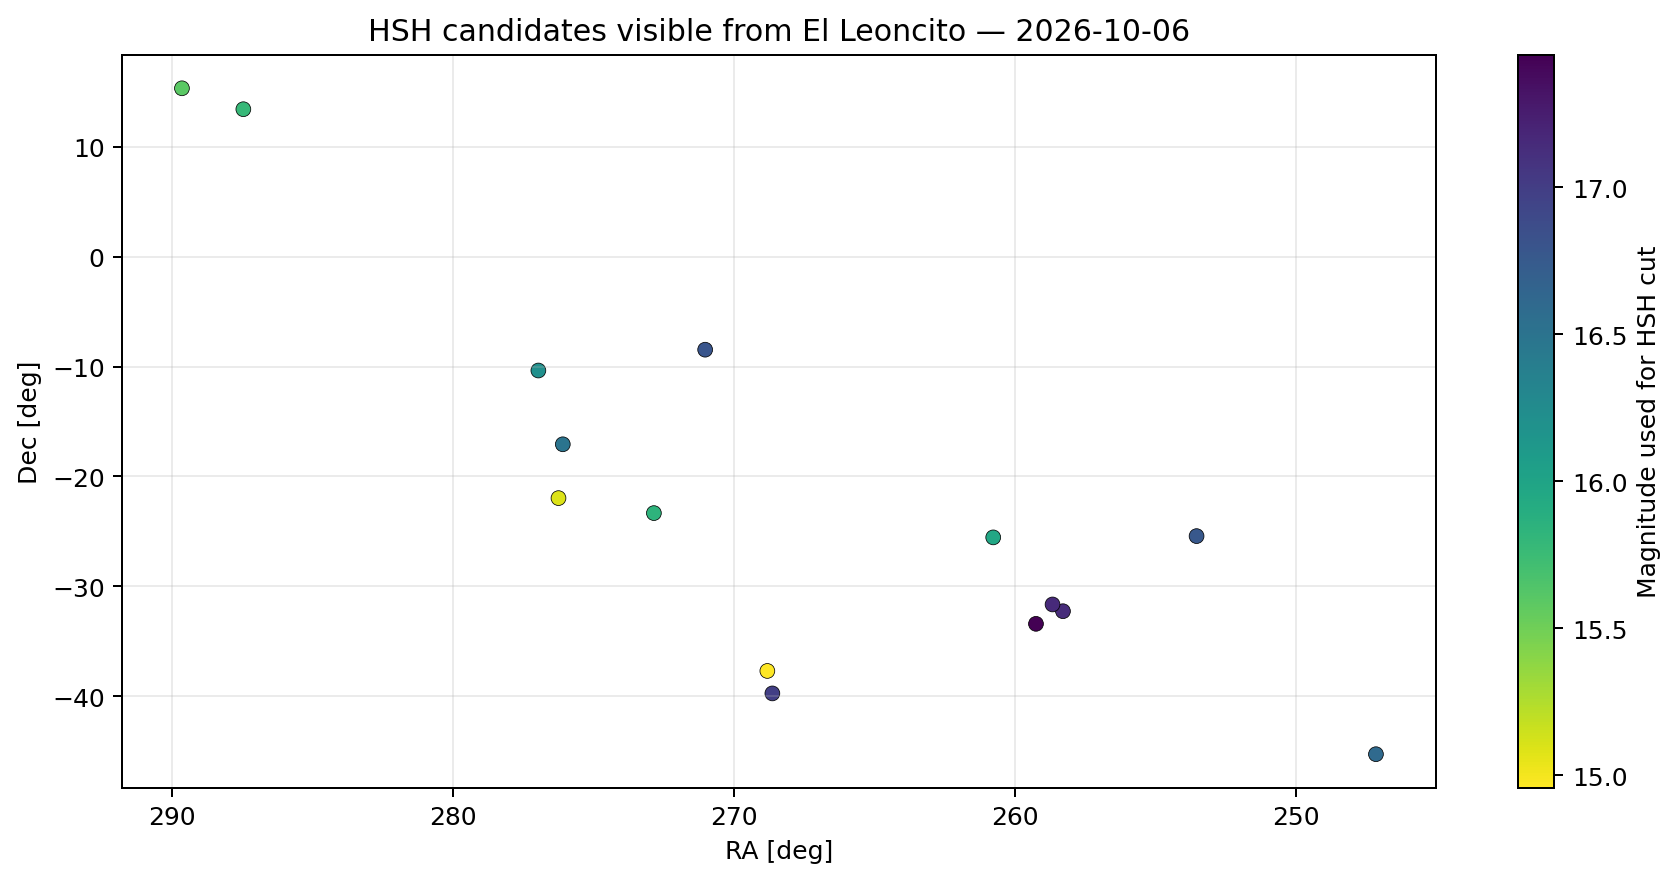

      visibility: 1/1 (2026-10-06, 182/221 selected, 10 plot(s))
Visibility PDF: /home/karennowo/target_selection/notebooks/v2/outputs/hsh_daily_selection/2026-10-06/hsh_visibility.pdf


In [5]:
fig, axis = plt.subplots(figsize=(10, 5), dpi=180)
scatter = axis.scatter(selected['ra_deg'] % 360, selected['dec_deg'], c=selected['magnitude_hsh'], s=35, cmap='viridis_r', edgecolor='black', linewidth=0.3)
axis.invert_xaxis()
axis.grid(alpha=0.25)
axis.set(xlabel='RA [deg]', ylabel='Dec [deg]', title=f'HSH candidates visible from El Leoncito — {OBSERVING_DATE}')
fig.colorbar(scatter, ax=axis, label='Magnitude used for HSH cut')
fig.tight_layout()
fig.savefig(OUTPUT / 'sky_map_selected_targets.png', bbox_inches='tight')
plt.show()

visibility.plots(candidates, start_date=OBSERVING_DATE, end_date=OBSERVING_DATE, output_dir=OUTPUT / 'visibility_plots', observatory=OBSERVATORY, minimum_altitude_deg=MIN_ALTITUDE_DEG, minimum_observable_minutes=MIN_VISIBLE_MINUTES, observing_windows=OBSERVING_WINDOW, selection=visibility_by_night, overwrite=True, verbose=True)
from visibility_plotter import compile_visibility_plot_pages
visibility_pdf = compile_visibility_plot_pages(OUTPUT / 'visibility_plots', OUTPUT / 'hsh_visibility.pdf')
print('Visibility PDF:', visibility_pdf)

## 5. Build the event-stage and priority table

Targets without MOP photometry are retained in the candidate and visibility tables but are not included in the event-stage priority table. Stage boundaries use the existing MOP/HSH summary convention based on `t0` and `tE`.

In [6]:
legacy = selected.rename(columns={'target_id': 'Target', 'ra_deg': 'RA_deg', 'dec_deg': 'Dec_deg', 'event_peak_hjd': 'mop_t_0_hjd', 'event_duration_days': 'mop_t_e_days', 'u0': 'mop_u_0', 'magnitude_hsh': 'mag_now'}).copy()
legacy = legacy.loc[:, ~legacy.columns.duplicated(keep='first')]
for column in ('mop_t_0_hjd', 'mop_t_e_days'):
    if column not in legacy:
        legacy[column] = np.nan
if len(legacy):
    stage_summary = build_observing_selection_summary(legacy, pd.DataFrame(), MOP_PHOTOMETRY_DIR, hsh_image_catalog=HSH_IMAGE_CATALOG if HSH_IMAGE_CATALOG.exists() else None, include_reference=False)
    if HSH_IMAGE_CATALOG.exists():
        stage_summary = stage_summary.merge(summarize_hsh_observations(legacy, HSH_IMAGE_CATALOG), on='Target', how='left', suffixes=('', '_hsh'))
    stage_summary = stage_summary.rename(columns={'Target': 'target_id'})
else:
    stage_summary = pd.DataFrame()

if len(stage_summary):
    stage_summary['mop_photometry_points_total'] = stage_summary.filter(regex=r'^mop_.*_points$').apply(pd.to_numeric, errors='coerce').fillna(0).sum(axis=1)
    priority = selected.merge(stage_summary, on='target_id', how='inner', suffixes=('', '_stages'))
    priority = priority.loc[priority['mop_photometry_points_total'].gt(0)].copy()
else:
    priority = pd.DataFrame()
priority.to_csv(OUTPUT / 'hsh_priority_table.csv', index=False)
print(f'Priority rows with MOP photometry: {len(priority):,}')
display(priority.head(20))

Priority rows with MOP photometry: 5


,target_id,Unnamed: 1,latest_mag_band,coordinates,opm_probability_score,Variability Flags Vizier,opm_days_since_created,Gaia N&sup2 Rescaled,ALeRCE microlensing BHRF Rescaled,ALeRCE microlensing BHRF Constrast,...,hsh_airmass_p90,hsh_quality_status,hsh_quality_scope,hsh_pre_baseline_n,hsh_rise_n,hsh_peak_n,hsh_fall_n,hsh_post_baseline_n,hsh_unknown_phase_n,mop_photometry_points_total
0,OGLE-2023-BLG-1273,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,not_observed,no_hsh_data,0,0,0,0,0,0,195
1,OGLE-2024-BLG-0808,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,not_observed,no_hsh_data,0,0,0,0,0,0,282
2,OGLE-2025-BLG-0242,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,not_observed,no_hsh_data,0,0,0,0,0,0,397
8,OGLE-2026-GD-0001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,not_observed,no_hsh_data,0,0,0,0,0,0,659
11,ZTF26aazuuhy,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,not_observed,no_hsh_data,0,0,0,0,0,0,759


## 6. Light-curve plots

This creates one plot per selected target using the cached MOP photometry. OPM candidate metadata are included in the target table; OPM light-curve downloading will be added to the normalized provider when its private target parser is completed.

In [7]:
if len(selected):
    report.create_lightcurve_plots(selected, output_dir=OUTPUT / 'lightcurves', mop_photometry_dir=MOP_PHOTOMETRY_DIR, overwrite=True, verbose=True)
else:
    print('No selected targets; no light-curve plots generated.')

[reports] Updating 15 light-curve PNG(s).


Light curves:   0%|          | 0/15 [00:00<?, ?target/s]

[reports] Light-curve PNGs ready: 15 in /home/karennowo/target_selection/notebooks/v2/outputs/hsh_daily_selection/2026-10-06/lightcurves


## 7. Optional DP2 coverage

This is disabled by default because the Rubin coverage query can take much longer than the daily visibility analysis. Set `RUN_DP2_MATCHING = True` in the first cell when DP2 coverage is needed.

In [8]:
if RUN_DP2_MATCHING and len(selected):
    from target_selection import open_collection
    collection = open_collection('DP2')
    coverage = collection.get_visit_coverage(selected, bands=tuple('ugrizy'), cache_dir=CACHE / 'dp2_visits', max_workers=DP2_WORKERS)
    coverage = collection.get_coadd_coverage(coverage, bands=tuple('ugrizy'), cache_path=CACHE / 'dp2_coadds.csv')
    coverage.to_csv(OUTPUT / 'dp2_coverage.csv', index=False)
    report.sky_maps(coverage, OUTPUT / 'dp2_sky_maps', bands=tuple('ugrizy'), name='HSH selected targets')
else:
    print('DP2 matching disabled.')

Visit tiles: 100%|██████████| 14/14 [00:00<00:00, 90.45tile/s]

Visit coverage: 14 spatial tiles, 15 targets, 47 target-band rows


## Outputs

The main decision products are `selected_hsh_targets.csv`, `visibility_by_night.csv`, `visibility_summary.csv`, `hsh_priority_table.csv`, `sky_map_selected_targets.png`, `hsh_visibility.pdf`, the `visibility_plots/` directory and the `lightcurves/` directory. The PDF is compiled from the same nightly PNGs that contain the altitude curves and the colored altitude-bar map.

## Selected-target summary PDF

This PDF contains only the final targets that pass both the HSH magnitude cut and the local visibility cut. It includes their altitude/bar visibility plots followed by one light curve per target, using all cached MOP filters, OPM photometry when available, and HSH observation epochs when available.

In [12]:
import importlib
importlib.reload(report)
selected_ids = set(selected['target_id'].astype(str))
selected_visibility_rows = visibility_by_night.loc[visibility_by_night['target_id'].astype(str).isin(selected_ids)].copy()
selected_visibility_dir = OUTPUT / 'selected_visibility_plots'
selected_visibility_pngs = visibility.plots(selected, start_date=OBSERVING_DATE, end_date=OBSERVING_DATE, output_dir=selected_visibility_dir, observatory=OBSERVATORY, minimum_altitude_deg=MIN_ALTITUDE_DEG, minimum_observable_minutes=MIN_VISIBLE_MINUTES, observing_windows=OBSERVING_WINDOW, selection=selected_visibility_rows, max_targets_per_plot=20, overwrite=True, verbose=True)

opm_points = pd.DataFrame()
opm_targets = selected.loc[selected.get('opm_target_page_id', pd.Series(np.nan, index=selected.index)).notna()].copy()
if len(opm_targets):
    opm_points = OPM.photometry(opm_targets, errors='ignore', verbose=True)
    if len(opm_points):
        opm_points['Target'] = opm_points['target_id'].astype(str)
        opm_points['Timestamp'] = pd.to_datetime(pd.to_numeric(opm_points['epoch_hjd'], errors='coerce') - 2440587.5, unit='D', origin='unix', errors='coerce', utc=True).dt.tz_localize(None)
        opm_points['Magnitude'] = pd.to_numeric(opm_points['magnitude'], errors='coerce')
        opm_points['Error'] = pd.to_numeric(opm_points.get('magnitude_err'), errors='coerce')
        opm_points['Filter'] = opm_points['band'].astype(str)
        opm_points['provider'] = 'OPM'

hsh_epochs = pd.DataFrame()
if HSH_IMAGE_CATALOG.exists():
    from observatory_observations import load_hsh_astrometry_catalog
    hsh_epochs = load_hsh_astrometry_catalog(HSH_IMAGE_CATALOG)
    hsh_epochs['Target'] = hsh_epochs['source_target'].astype(str)
    hsh_epochs['provider'] = 'HSH'
    hsh_epochs = hsh_epochs.loc[hsh_epochs['target_key'].isin(selected['target_key'].astype(str))].copy()

selected_report = selected.copy()
selected_report['Target'] = selected_report['target_id'].astype(str)
selected_report['mag_now'] = selected_report['magnitude_hsh']
selected_report['mop_t_0_hjd'] = selected_report.get('event_peak_hjd', np.nan)
selected_report['mop_t_e_days'] = selected_report.get('event_duration_days', np.nan)
lightcurve_pngs = report.create_lightcurve_plots(selected_report, output_dir=OUTPUT / 'selected_lightcurves', mop_photometry_dir=MOP_PHOTOMETRY_DIR, observatory_epochs=hsh_epochs, observatory_photometry=opm_points, layers=('mop_photometry', 'hsh', 'opm_photometry'), mop_filters='all', overwrite=True, verbose=True)
selected_summary_pdf = report.selection_summary_pdf(selected_visibility_pngs, lightcurve_pngs, OUTPUT / 'selected_targets_summary.pdf')
print(f'Selected-target summary PDF: {selected_summary_pdf}')

      visibility: 1/1 (2026-10-06, 15/15 selected, 1 plot(s))
[reports] Updating 15 light-curve PNG(s).


Light curves:   0%|          | 0/15 [00:00<?, ?target/s]

[reports] Light-curve PNGs ready: 15 in /home/karennowo/target_selection/notebooks/v2/outputs/hsh_daily_selection/2026-10-06/selected_lightcurves
Selected-target summary PDF: /home/karennowo/target_selection/notebooks/v2/outputs/hsh_daily_selection/2026-10-06/selected_targets_summary.pdf
